# 02 - Modeling & Evaluation

Trains and compares several classification models to predict `Revenue` (purchase intention):

- Logistic Regression (baseline, interpretable)
- Decision Tree
- Random Forest
- XGBoost (Gradient Boosting)

Evaluated with accuracy, precision, recall, F1-score, confusion matrix and AUC-ROC (as required by the assignment). Outputs a metrics comparison table and per-session predictions CSV for the Power BI dashboard.

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_auc_score, roc_curve, ConfusionMatrixDisplay,
)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

project_folder = Path.cwd().parent
cleaned_path = project_folder / "dataset" / "online_shoppers_intention_cleaned.csv"
results_folder = project_folder / "dataset" / "results"
results_folder.mkdir(exist_ok=True)

df = pd.read_csv(cleaned_path)
print("Shape:", df.shape)
df.head()

Shape: (12205, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


## 1. Preprocessing

- `Month` and `VisitorType` are one-hot encoded (nominal categories, no natural order).
- `Weekend` and `Revenue` are boolean -> converted to 0/1.
- `OperatingSystems`, `Browser`, `Region`, `TrafficType` are already integer-coded categorical IDs in the source dataset; we leave them as numeric here for simplicity (a limitation worth naming in the report — a stricter approach would one-hot encode these too, at the cost of many extra columns).

In [2]:
data = df.copy()
data["Weekend"] = data["Weekend"].astype(int)
data["Revenue"] = data["Revenue"].astype(int)

data = pd.get_dummies(data, columns=["Month", "VisitorType"], drop_first=True)

X = data.drop(columns=["Revenue"])
y = data["Revenue"]
feature_names = X.columns.tolist()

print("Features:", len(feature_names))
X.head()

Features: 26


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,...,Month_Feb,Month_Jul,Month_June,Month_Mar,Month_May,Month_Nov,Month_Oct,Month_Sep,VisitorType_Other,VisitorType_Returning_Visitor
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,...,True,False,False,False,False,False,False,False,False,True
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,...,True,False,False,False,False,False,False,False,False,True
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,...,True,False,False,False,False,False,False,False,False,True
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,...,True,False,False,False,False,False,False,False,False,True
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,...,True,False,False,False,False,False,False,False,False,True


## 2. Train / Test Split

`stratify=y` keeps the ~85/15 purchase imbalance consistent between train and test sets.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, "Test:", X_test.shape)
print("Train purchase rate:", y_train.mean().round(3))
print("Test purchase rate:", y_test.mean().round(3))

Train: (9764, 26) Test: (2441, 26)
Train purchase rate: 0.156
Test purchase rate: 0.156


In [4]:
# Logistic Regression is sensitive to feature scale; tree-based models are not.
# We fit the scaler on train only, to avoid leaking test-set information.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 3. Train Models

Class imbalance (~85% no-purchase) is handled via `class_weight="balanced"` (Logistic Regression, Decision Tree, Random Forest) and `scale_pos_weight` (XGBoost), rather than resampling — so training still reflects the real-world proportions while giving the minority (purchase) class more weight.

In [ ]:
neg, pos = (y_train == 0).sum(), (y_train == 1).sum()
scale_pos_weight = neg / pos

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=8, class_weight="balanced", random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, max_depth=12, class_weight="balanced", random_state=RANDOM_STATE
    ),
    "XGBoost": XGBClassifier(
        n_estimators=300, max_depth=6, learning_rate=0.1,
        scale_pos_weight=scale_pos_weight, eval_metric="logloss",
        random_state=RANDOM_STATE,
    ),
}

# Logistic Regression uses the scaled features; tree-based models use raw features.
uses_scaled = {"Logistic Regression"}

fitted_models = {}
for name, model in models.items():
    if name in uses_scaled:
        model.fit(X_train_scaled, y_train)
    else:
        model.fit(X_train, y_train)
    fitted_models[name] = model
    print(f"Trained: {name}")

Trained: Logistic Regression
Trained: Decision Tree


Trained: Random Forest


Trained: XGBoost


## 4. Evaluate All Models

In [6]:
metrics_rows = []
roc_curves = {}
predictions_by_model = {}

for name, model in fitted_models.items():
    X_eval = X_test_scaled if name in uses_scaled else X_test
    y_pred = model.predict(X_eval)
    y_proba = model.predict_proba(X_eval)[:, 1]

    metrics_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "AUC-ROC": roc_auc_score(y_test, y_proba),
    })

    roc_curves[name] = roc_curve(y_test, y_proba)
    predictions_by_model[name] = y_proba

metrics_df = pd.DataFrame(metrics_rows).set_index("Model").round(4)
metrics_df

,Accuracy,Precision,Recall,F1-Score,AUC-ROC
Model,,,,,
Logistic Regression,0.8513,0.5164,0.7853,0.6231,0.9110
Decision Tree,0.8607,0.5376,0.7853,0.6383,0.8877
Random Forest,0.8746,0.5709,0.8010,0.6667,0.9316
XGBoost,0.8873,0.6166,0.7408,0.6730,0.9252


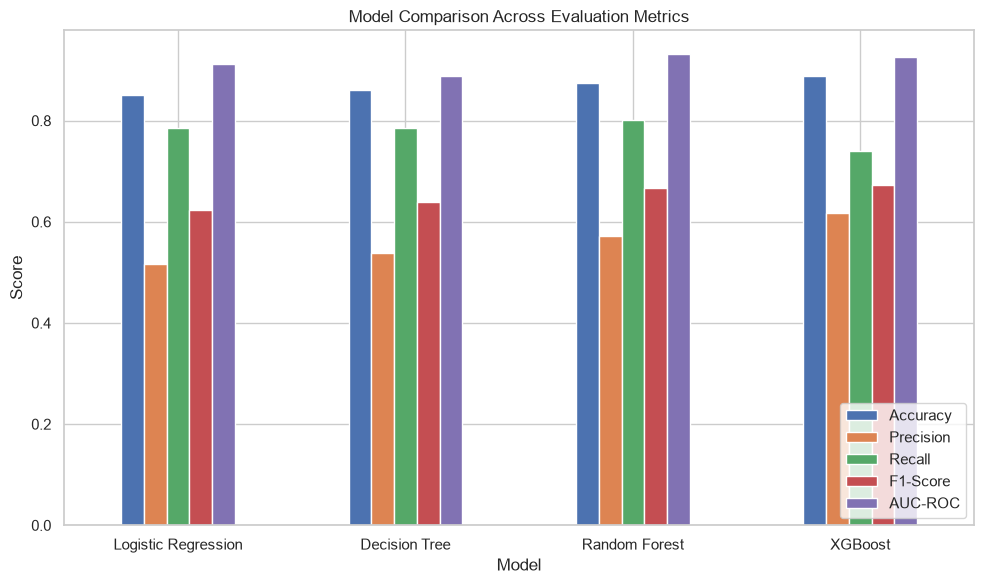

In [7]:
metrics_df.plot(kind="bar", figsize=(10, 6), rot=0)
plt.title("Model Comparison Across Evaluation Metrics")
plt.ylabel("Score")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 5. Confusion Matrices

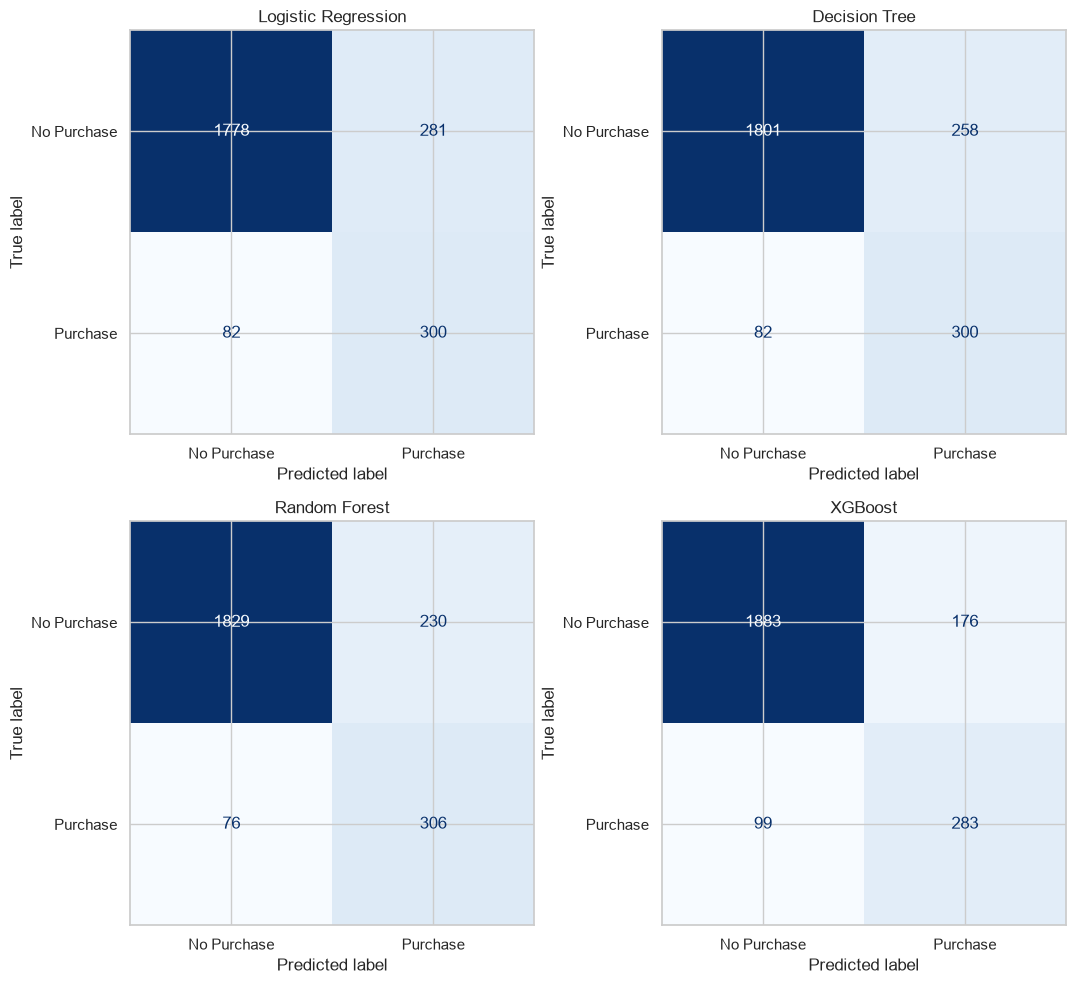

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(11, 10))
for ax, (name, model) in zip(axes.ravel(), fitted_models.items()):
    X_eval = X_test_scaled if name in uses_scaled else X_test
    y_pred = model.predict(X_eval)
    cm = confusion_matrix(y_test, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=["No Purchase", "Purchase"]).plot(
        ax=ax, colorbar=False, cmap="Blues"
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()

## 6. ROC Curves

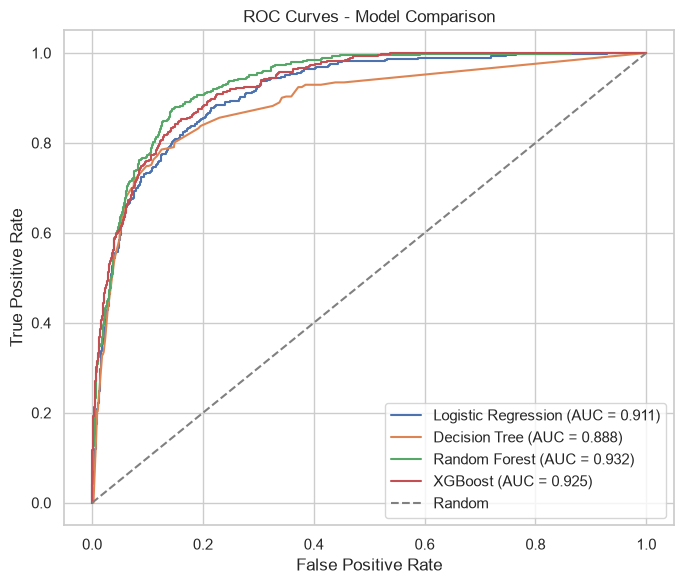

In [9]:
fig, ax = plt.subplots(figsize=(7, 6))
for name, (fpr, tpr, _) in roc_curves.items():
    auc = metrics_df.loc[name, "AUC-ROC"]
    ax.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curves - Model Comparison")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 7. Feature Importance (Random Forest)

Directly supports Research Objective 4 — identifying the features with the greatest influence on purchase intention.

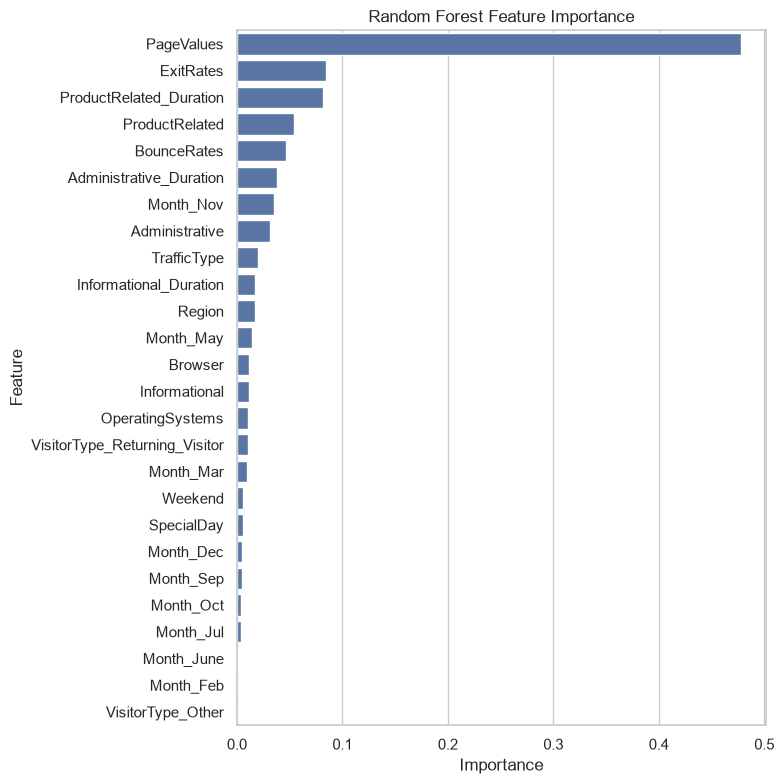

,Feature,Importance
0,PageValues,0.477565
1,ExitRates,0.084800
2,ProductRelated_Duration,0.081167
3,ProductRelated,0.053603
4,BounceRates,0.046483
5,Administrative_Duration,0.038394
6,Month_Nov,0.035057
7,Administrative,0.031102
8,TrafficType,0.020036
9,Informational_Duration,0.017123


In [10]:
rf = fitted_models["Random Forest"]
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf.feature_importances_,
}).sort_values("Importance", ascending=False).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(8, 8))
sns.barplot(x="Importance", y="Feature", data=importance_df, ax=ax)
ax.set_title("Random Forest Feature Importance")
plt.tight_layout()
plt.show()

importance_df.head(10)

## 8. Export Results for Power BI

Two CSVs go to `dataset/results/`:
- `model_metrics_comparison.csv` — one row per model, for Table/quantitative-results in the report and a Power BI bar chart.
- `test_predictions.csv` — every test-set session with its true label, each model's predicted probability, and the original features, for building purchase-rate-by-segment visuals in Power BI.

In [11]:
metrics_df.reset_index().to_csv(results_folder / "model_metrics_comparison.csv", index=False)
importance_df.to_csv(results_folder / "feature_importance_rf.csv", index=False)

predictions_export = X_test.copy()
predictions_export["Actual_Revenue"] = y_test.values
for name, proba in predictions_by_model.items():
    col_name = name.replace(" ", "_") + "_Predicted_Probability"
    predictions_export[col_name] = proba

predictions_export.to_csv(results_folder / "test_predictions.csv", index=False)

print("Saved:")
print(" -", results_folder / "model_metrics_comparison.csv")
print(" -", results_folder / "feature_importance_rf.csv")
print(" -", results_folder / "test_predictions.csv")

Saved:
 - C:\Users\khais\OneDrive - Sunway Education Group\SWA Final Assessment\SWA2124-Final-Assignment-Online-Shoppers-Project\dataset\results\model_metrics_comparison.csv
 - C:\Users\khais\OneDrive - Sunway Education Group\SWA Final Assessment\SWA2124-Final-Assignment-Online-Shoppers-Project\dataset\results\feature_importance_rf.csv
 - C:\Users\khais\OneDrive - Sunway Education Group\SWA Final Assessment\SWA2124-Final-Assignment-Online-Shoppers-Project\dataset\results\test_predictions.csv


## 9. Best Model Summary

In [12]:
best_model_name = metrics_df["AUC-ROC"].idxmax()
print(f"Best model by AUC-ROC: {best_model_name}")
metrics_df.loc[[best_model_name]]

Best model by AUC-ROC: Random Forest


,Accuracy,Precision,Recall,F1-Score,AUC-ROC
Model,,,,,
Random Forest,0.8746,0.5709,0.801,0.6667,0.9316
